In [1]:
import sys

sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from classes.loader.loader import Loader
from classes.feature import WPTFeatureExtractor, PSDFeatureExtractor, RMSFeatureExtractor
from classes.common import Cables

ModuleNotFoundError: No module named 'classes'

In [ ]:
PATH_TO_TRAIN_DATASET = r"../raw/sequence_2/"
PATH_TO_VALID_DATASET = r"../raw/sequence_1/"
PATH_TO_TEST_DATASET = r"../raw/sequence_3/"
PATH_TO_RAW_EXAMPLE = r"../raw/time_examples/2022_11_16_19_44.json"

In [ ]:
import os
import json
import plotly.express as px
import plotly.graph_objects as go

In [ ]:
with open(PATH_TO_RAW_EXAMPLE, "r") as h:
    d = json.load(h)

# Single files

In [ ]:
loader = Loader(PATH_TO_TRAIN_DATASET)
f1 = loader.load_one("2023_01_17_15_37.json")
f2 = loader.load_one("2023_01_29_02_01.json")
f3 = loader.load_one("2023_02_01_12_59.json")
f4 = loader.load_one("2023_02_10_15_30.json")

samples = [f1, f2, f3, f4]
for sample in samples:
    sample.convert_to_time()

In [ ]:
c1_tension = [sample.sample_c1.tension for sample in samples]

In [113]:
from scipy.signal import welch, hilbert
from classes.sample import Sample, SingleSample, SampleTypes
from classes.signal import SignalTime


def get_spectrum(signal, nperseg):
    t, x = signal.get()
    fs = 1 / signal.ts
    f, xx = welch(x - np.mean(x), fs, nperseg=nperseg)
    return f, xx

def get_fft(signal):
    t, x = signal.get()
    ts = signal.ts
    x = x - np.mean(x)
    xx = np.abs(np.fft.rfft(x))
    f = np.fft.rfftfreq(len(x), ts)
    return f, xx

def bandpass(signal: SignalTime, f0: float, f1: float) -> SignalTime:
    #sos = butter(N=N, Wn=[f0, f1], btype="bandpass", fs=1 / signal.ts, output="sos")
    #filtered = sosfilt(sos, signal.signal)
    #return SignalTime(signal=filtered, ts=signal.ts, id=signal.id)

    x = np.fft.fft(signal.signal)
    f = np.fft.fftfreq(len(signal), signal.ts)
    idx = (np.abs(f) > f0) & (np.abs(f) < f1)
    new_x = x * 0
    new_x[idx] = x[idx]
    new_s = np.fft.ifft(new_x)
    return SignalTime(np.real(new_s), signal.ts, None)

def get_envelope(signal: SignalTime) -> SignalTime:
    h = hilbert(np.array(signal.signal))
    return SignalTime(signal=list(np.abs(h)), ts=signal.ts, id=signal.id)

In [107]:
fig = go.Figure()
for sample in samples:
    f, xx = get_spectrum(sample.sample_c4.y, 8000)
    xx  = 20 * np.log10(xx)
    fig.add_trace(go.Scatter(x=f, y=xx, name=sample.sample_c1.tension))
fig.show()

In [142]:
fig = go.Figure()
for sample in samples:
    signal = sample.sample_c2.z
    signal.signal = np.square(signal.signal)
    tension = sample.sample_c1.tension

    signal = bandpass(signal, 1, 8)
    env = get_envelope(signal)
    f, xx = get_fft(env)
    xx  = 20 * np.log10(xx)
    fig.add_trace(go.Scatter(x=f, y=xx, name=tension))
fig.show()

# RMS

In [5]:
rms_transformer = RMSFeatureExtractor(axis_to_combine=["y", "z"])
loader = Loader(PATH_TO_VALID_DATASET, rms_transformer)
dfs_per_cable = loader.load_from_folder()

 22%|██▏       | 596/2730 [04:19<15:28,  2.30it/s]


KeyboardInterrupt: 

In [ ]:
x = [np.vstack(dfs_per_cable[c].features.to_list()).squeeze() for c in Cables]

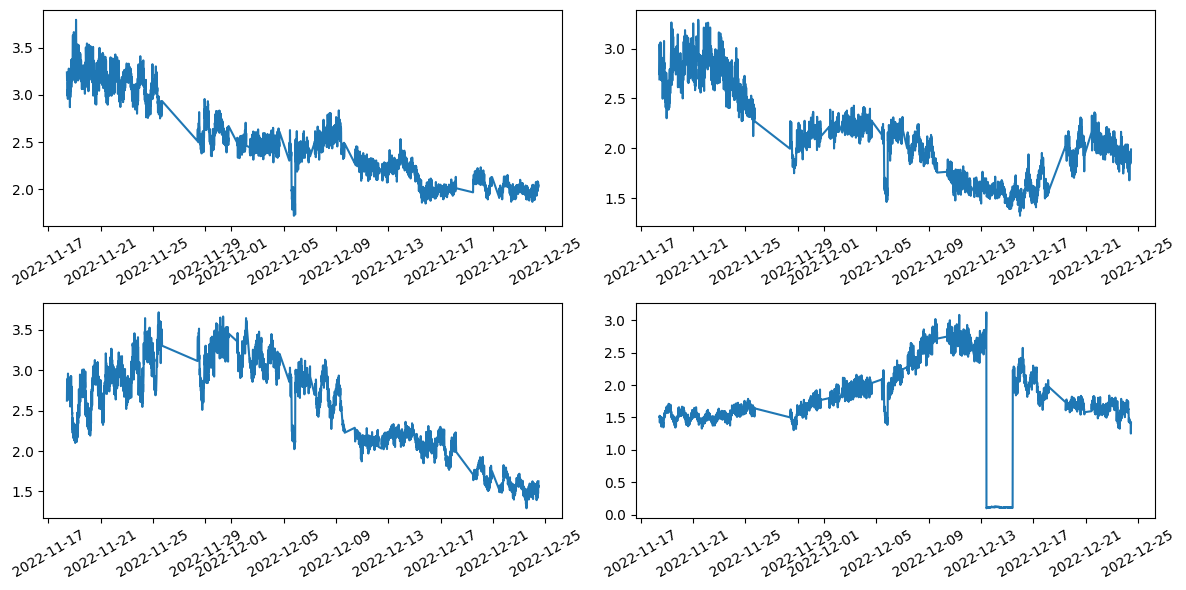

In [ ]:
plt.figure(figsize=(12,6))
dates = dfs_per_cable[Cables.C1].sampled_at
for i in range(4):
    plt.subplot(2,2,i+1)
    plt.plot(dates, x[i])
    plt.xticks(rotation=30);
plt.tight_layout()

# PSD

In [6]:
psd_transformer = PSDFeatureExtractor(nperseg=1024, poverlap=0.5)
loader = Loader(PATH_TO_TEST_DATASET, psd_transformer)
dfs_per_cable = loader.load_from_folder()

100%|██████████| 6238/6238 [15:28<00:00,  6.72it/s]  


Text(0.5, 0, 'Sample number')

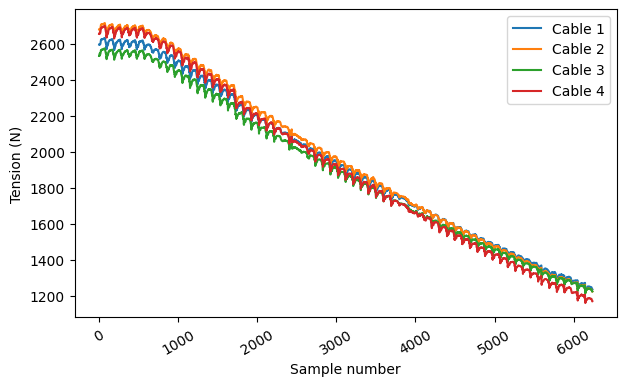

In [ ]:
plt.figure(figsize=(7,4))

for c, df in dfs_per_cable.items():
    plt.plot(df.tension)

plt.legend([f"Cable {c.value}" for c in dfs_per_cable.keys()])
plt.xticks(rotation=30);
plt.ylabel("Tension (N)")
plt.xlabel("Sample number")


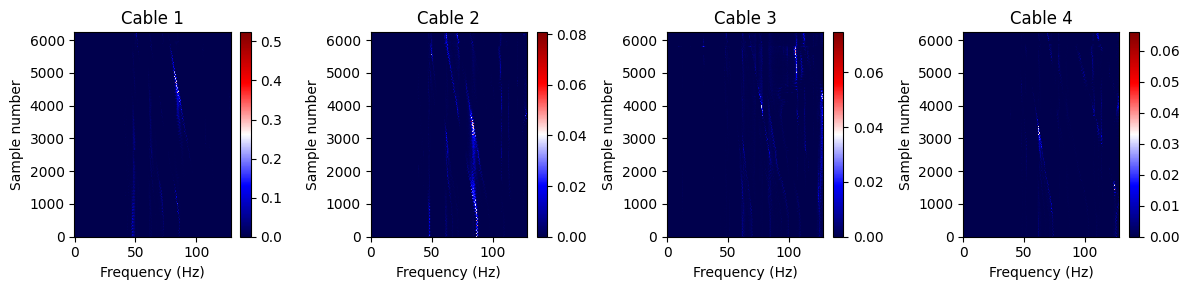

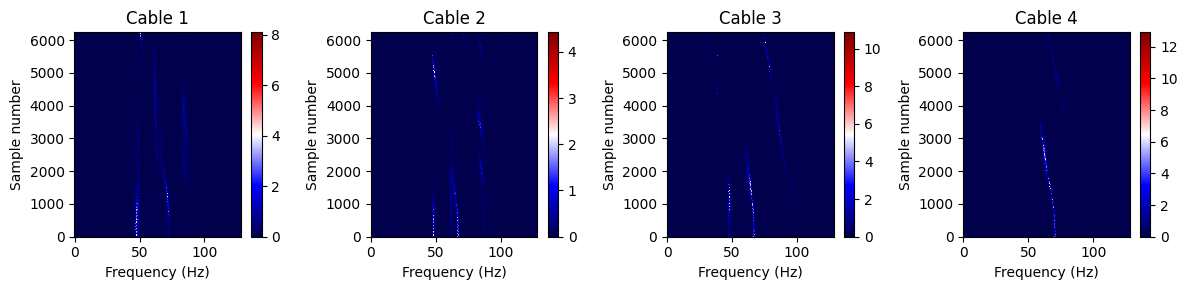

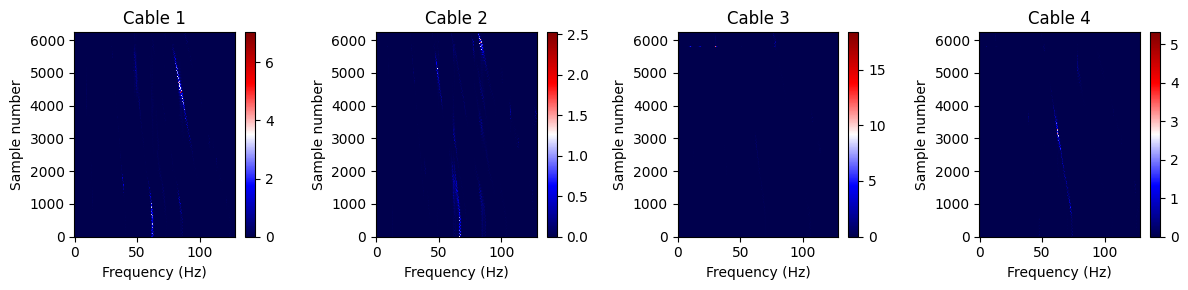

In [15]:
for axis in range(3):
    plt.figure(figsize=(12,3))
    for c in Cables:
        psd = np.vstack(dfs_per_cable[c].features.to_list())
        fs = 256
        df = (fs/2) / len(psd)
        f = np.linspace(df,fs/2,psd.shape[-1])
        plt.subplot(1,4,c.value)
        samples = np.arange(len(psd))
        plt.pcolormesh(f, samples, psd[:,axis,:], cmap="seismic")
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Sample number")
        plt.title(f"Cable {c.value}")
        plt.colorbar()
    plt.tight_layout()

# WPT

In [16]:
wpt_transformer = WPTFeatureExtractor(family="db4", level=6, normalize=True, axis_to_combine=["y", "z"])
loader = Loader(PATH_TO_TEST_DATASET, wpt_transformer)
dfs_per_cable = loader.load_from_folder()

100%|██████████| 6238/6238 [05:12<00:00, 19.97it/s]


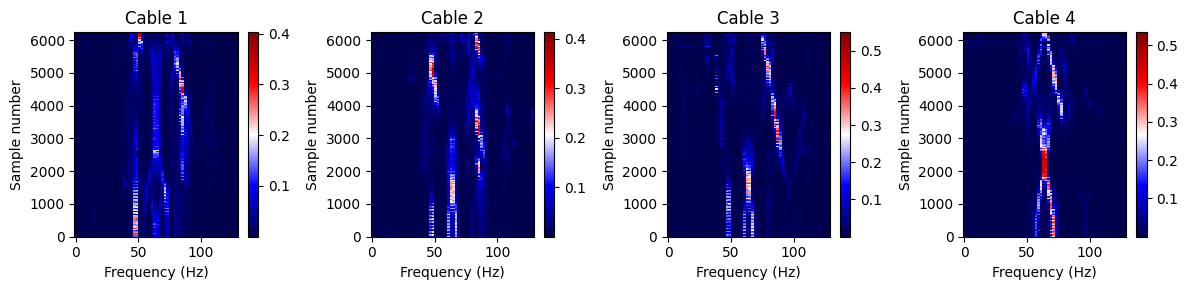

In [17]:
for axis in range(1):
    plt.figure(figsize=(12,3))
    for c in Cables:
        wpt = np.vstack(dfs_per_cable[c].features.to_list())
        fs = 256
        df = (fs/2) / len(wpt)
        f = np.linspace(df, fs/2, wpt.shape[-1])
        plt.subplot(1, 4, c.value)
        samples = np.arange(len(wpt))
        plt.pcolormesh(f, samples, wpt[:,axis,:], cmap="seismic")
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Sample number")
        plt.title(f"Cable {c.value}")
        plt.colorbar()
    plt.tight_layout()